In [13]:
# Re-import and re-plot
import matplotlib.pyplot as plt
import numpy as np

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

In [14]:
# Gradient descent finds the bottom of the bowl by walking downhill: 
# 1. Start at any point, such as theta0 = 0 and theta1 = 0.
# 2. Look at which direction is steepest downhill (the gradient, the slope of the cost surface there).
# 3. Take a small step that way.
# 4. Repeat until the slope is about zero, meaning you're at the bottom.

def linear_regression(X, y, theta0=0, theta1=0, epochs=10000, learning_rate=0.01):
    N = float(len(y))
    for i in range(epochs):
        y_hyp = theta1 * X + theta0
        cost = np.sum((y - y_hyp) ** 2) / N
        theta1 -= learning_rate * -(2/N) * np.sum(X * (y - y_hyp))
        theta0 -= learning_rate * -(2/N) * np.sum(y - y_hyp)
    return theta0, theta1, cost

theta0, theta1, cost = linear_regression(X, y)
print(theta0, theta1, cost)


3.839576253455361 3.0803485179783876 0.9731557881811607


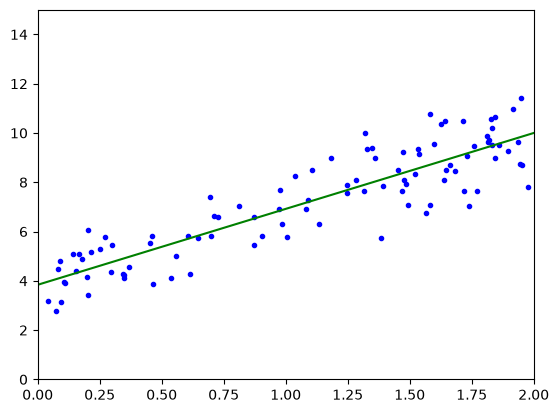

In [15]:
# We use the thetas (x,y) found with the gradient descent with lowest cost score

theta0, theta1, cost = linear_regression(X, y)

plt.plot(X, y, "b.")
plt.axis([0, 2, 0, 15])

X_new = np.array([[0], [2]])
y_predict = theta0 + theta1 * X_new
plt.plot(X_new, y_predict, "g-")
plt.show()

In [16]:
# Ex 1.6 Math can do this directly!

X_b = np.c_[np.ones((100, 1)), X]
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
print(theta_best)

[[3.83957625]
 [3.08034852]]


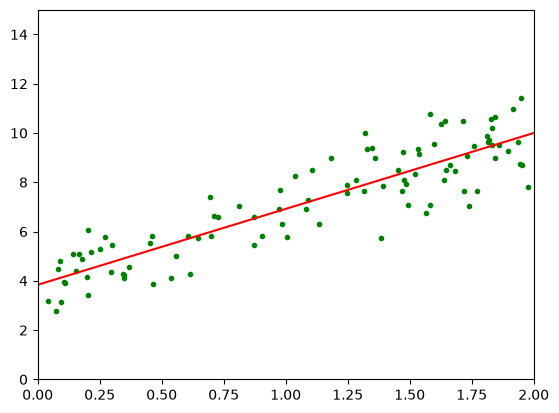

In [17]:
# And this is how the line looks calculated with MATH
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b.dot(theta_best)

plt.plot(X, y, "g.")
plt.axis([0, 2, 0, 15])
plt.plot(X_new, y_predict, "r-")
plt.show()

[3.83957625] [[3.08034852]]


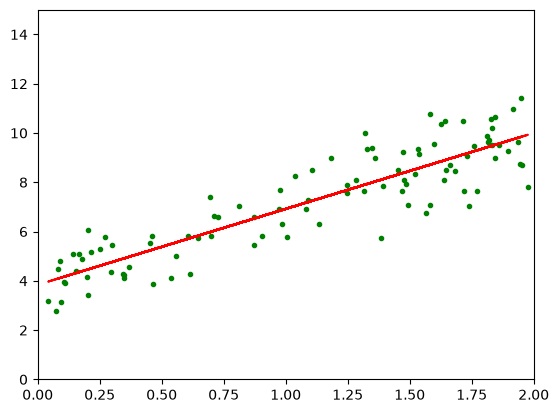

In [ ]:
# Getting the thetas using a library "sklearn"
from sklearn import linear_model

lm = linear_model.LinearRegression()
model = lm.fit(X, y)

print(lm.intercept_, lm.coef_)


f = lambda x: lm.coef_ * x + lm.intercept_
plt.plot(X, y, "g.")
plt.axis([0, 2, 0, 15])
plt.plot(X, f(X), c="red")
plt.show()